# Bài 06: Trích xuất Đặc trưng Ảnh (HOG, LBP, Color Histogram) và 7 Mô hình Machine Learning Truyền thống

## 1. Mục tiêu học tập
- Phân biệt rõ ràng giữa **Phương pháp Trích xuất Đặc trưng (`Feature Extraction`)** và **Mô hình Phân loại (`Classification Model`)**:
  - **Nhóm Trích xuất Đặc trưng**: `Pixel Flattening` (Baseline), `Color Histogram`, `HOG (Histogram of Oriented Gradients)` và `LBP (Local Binary Patterns)`. Chúng biến bức ảnh thành vector số thực nhưng **không tự đưa ra nhãn lớp**.
  - **Nhóm Mô hình Phân loại**: Nhận vector đặc trưng để học quy luật phân chia lớp: `k-NN`, `Logistic Regression`, `Naive Bayes`, `Decision Tree`, `Random Forest`, `SVM`, và `Gradient Boosting`.
- Thực hành huấn luyện thật và so sánh công bằng cả 7 mô hình trên **cùng một cách chia dữ liệu (`Train / Val / Test`)** và **cùng bộ độ đo (`Accuracy`, `Macro-F1`, `Precision`, `Recall`)**.

## 2. Kiến thức cần có
- Đã hoàn thành Bài 04 và Bài 05.

## 3. Thời gian học dự kiến
- Khoảng **3.0 giờ** (ước tính).

## 4. Bài toán thực tế đơn giản
Bạn cần phân loại 4 loại chi tiết hình học (`circle`, `square`, `triangle`, `cross`) trên máy tính chỉ có CPU, dung lượng bộ nhớ hạn chế và yêu cầu thời gian huấn luyện dưới 2 giây. Thay vì ném thẳng `3072` giá trị pixel thô dễ nhiễu vào mô hình, việc rút trích đúng đặc trưng cạnh (`HOG`) và kết cấu (`LBP`) sẽ giúp các mô hình ML truyền thống đạt độ chính xác cao.

## 5. Giải thích trực quan: 4 Phương pháp Biểu diễn & Trích xuất Đặc trưng Ảnh
1. **Pixel Flattening (Trải phẳng điểm ảnh làm Baseline)**: Duỗi thẳng ảnh `(32, 32, 3)` thành vector `(3072,)`. Nhược điểm: Rất nhạy cảm khi vật thể dịch chuyển nhẹ vài pixel hoặc đổi độ sáng.
2. **Color Histogram (Biểu đồ tần suất màu)**: Đếm tỷ lệ màu sắc trong ảnh. Bất biến với phép dịch chuyển và xoay, nhưng **bỏ qua hoàn toàn hình dáng không gian**.
3. **HOG (Histogram of Oriented Gradients)**: Chia ảnh thành lưới các ô nhỏ (`cell_size = 8x8`), trong mỗi ô tính độ lớn và hướng góc (`0..180°`) của đạo hàm biên rồi lập histogram `9` ngăn góc. **Rất mạnh để bắt hình dáng và đường nét vật thể**.
4. **LBP (Local Binary Patterns)**: Tại mỗi pixel, so sánh độ sáng của nó với 8 lân cận xung quanh (lớn hơn hoặc bằng thì ghi bit `1`, nhỏ hơn ghi bit `0`), tạo thành số nguyên 8-bit (`0..255`). **Rất mạnh để mô tả kết cấu bề mặt (texture)**.

## 6. Thuật ngữ mới & Giải thích Keyword trong 7 Mô hình ML
| Mô hình & Keyword chính | Nhóm | Định nghĩa, Giá trị chọn & Ảnh hưởng khi Tăng/Giảm |
|---|---|---|
| `KNeighborsClassifier(n_neighbors=5, metric='euclidean')` | ML Phân loại | Bầu chọn theo `k = n_neighbors` điểm gần nhất. **Giảm `k=1`**: biên quyết định phức tạp, nhạy nhiễu (overfit). **Tăng `k` quá lớn**: biên quá trơn, dễ underfit. |
| `LogisticRegression(C=1.0, max_iter=500)` | ML Phân loại | Phân loại tuyến tính với phạt chuẩn $L_2$. Tham số `C` là **nghịch đảo cường độ điều chuẩn** ($C = 1/\lambda$): **Tăng `C`** → giảm phạt (dễ overfit hơn); **Giảm `C`** → phạt mạnh (trọng số co nhỏ). |
| `GaussianNB(var_smoothing=1e-9)` | ML Phân loại | Giả định các đặc trưng trong mỗi lớp tuân theo phân phối chuẩn độc lập. `var_smoothing` cộng thêm phương sai nhỏ để tránh lỗi chia cho `0`. |
| `DecisionTreeClassifier(max_depth=6, criterion='gini')` | ML Phân loại | Cây quyết định rẽ nhánh theo độ tạp `gini` hoặc `entropy`. Không giới hạn `max_depth=None` sẽ làm cây mọc tới khi mỗi lá chỉ còn 1 mẫu (Overfitting nặng!). |
| `RandomForestClassifier(n_estimators=100, max_depth=8)` | ML Ensemble | Tổ hợp `n_estimators` cây quyết định độc lập (Bagging). Tăng `n_estimators` giúp giảm phương sai dự đoán nhưng tăng thời gian tính toán tuyến tính. |
| `SVC(C=2.0, kernel='rbf', gamma='scale')` | ML Phân loại | Máy vector hỗ trợ (SVM) với nhân `RBF` ($K(x, x') = \exp(-\gamma \|x - x'\|^2)$). Tăng `C` hoặc tăng `gamma` làm biên uốn sát quanh từng điểm dữ liệu (dễ overfit). |
| `HistGradientBoostingClassifier(learning_rate=0.1, max_iter=100)` | ML Boosting | Xây dựng chuỗi cây sửa lỗi phần dư nối tiếp nhau (cùng họ với **XGBoost**, **LightGBM**, **CatBoost**). Giảm `learning_rate` kết hợp tăng `max_iter` thường giúp tổng quát hóa tốt hơn. |

## 7. Công thức Toán học Cốt lõi & Ví dụ Số Nhỏ
- **Công thức mã LBP tại tâm $(y_c, x_c)$ có độ sáng $g_c$ và 8 điểm lân cận $g_p$ ($p=0..7$)**:
  $$\text{LBP}(y_c, x_c) = \sum_{p=0}^{7} s(g_p - g_c) \cdot 2^p, \quad \text{với } s(z) = \begin{cases} 1 & \text{nếu } z \ge 0 \\ 0 & \text{nếu } z < 0 \end{cases}$$
- **Ví dụ số nhỏ LBP**: Nếu pixel tâm có $g_c = 50$ và 8 lân cận theo chiều kim đồng hồ là `[60, 55, 40, 30, 50, 70, 20, 10]`, chuỗi bit so sánh là `[1, 1, 0, 0, 1, 1, 0, 0]` $\implies \text{LBP} = 2^0 + 2^1 + 2^4 + 2^5 = 1 + 2 + 16 + 32 = 51$.


In [1]:
# Cell 1: Tạo dữ liệu, chia tập Stratified (Train/Val/Test) và Trích xuất 4 loại Đặc trưng Ảnh
import sys
import time
from pathlib import Path

current_dir = Path.cwd().resolve()
project_root = current_dir.parent if current_dir.name == "notebooks" else current_dir
if (project_root / "image_ai_learning").is_dir():
    project_root = project_root / "image_ai_learning"
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from src.utils import set_seed
from src.synthetic_data import generate_synthetic_shapes_dataset
from src.features import (
    extract_pixel_flatten,
    extract_color_histogram,
    extract_hog_manual,
    extract_lbp_manual,
    extract_combined_features,
)
from src.evaluation import compute_classification_metrics

QUICK_RUN = True
set_seed(42)

n_samples = 320 if QUICK_RUN else 600
ds = generate_synthetic_shapes_dataset(num_samples=n_samples, image_size=32, seed=42, noise_std=10.0)
images, labels, class_names = ds["images"], ds["labels"], ds["class_names"]

# Chia tập TRƯỚC khi trích xuất và chuẩn hóa
idx_all = np.arange(len(images))
idx_tr, idx_temp = train_test_split(idx_all, test_size=0.30, random_state=42, stratify=labels)
idx_va, idx_te = train_test_split(idx_temp, test_size=0.50, random_state=42, stratify=labels[idx_temp])

f_pix = extract_pixel_flatten(images)
f_col = extract_color_histogram(images, bins_per_channel=8)
f_hog = extract_hog_manual(images, cell_size=8, num_bins=9)
f_lbp = extract_lbp_manual(images, num_bins=16)
f_comb = extract_combined_features(images, cell_size=8)

print(f"1. Pixel Flattening shape : {f_pix.shape} (32*32*3 = 3072 chiều)")
print(f"2. Color Histogram shape  : {f_col.shape} (3*8 = 24 chiều)")
print(f"3. HOG Feature shape      : {f_hog.shape} (4*4 ô * 9 góc = 144 chiều)")
print(f"4. LBP Feature shape      : {f_lbp.shape} (16 ngăn kết cấu)")
print(f"5. Combined Feature shape : {f_comb.shape} (144 + 24 + 16 = 184 chiều)")


1. Pixel Flattening shape : (320, 3072) (32*32*3 = 3072 chiều)
2. Color Histogram shape  : (320, 24) (3*8 = 24 chiều)
3. HOG Feature shape      : (320, 144) (4*4 ô * 9 góc = 144 chiều)
4. LBP Feature shape      : (320, 16) (16 ngăn kết cấu)
5. Combined Feature shape : (320, 184) (144 + 24 + 16 = 184 chiều)


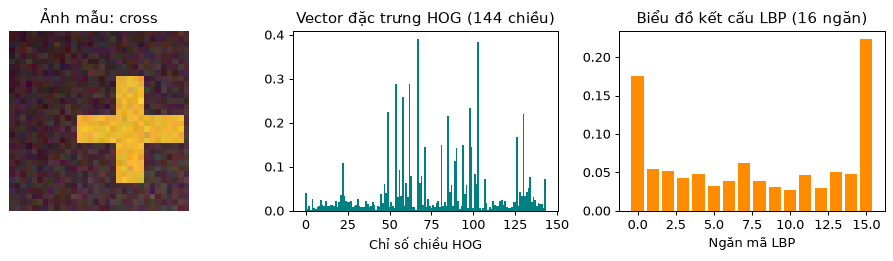

In [2]:
# Cell 2: Minh họa trực quan Đặc trưng HOG và LBP trên 1 mẫu ảnh
sample_img = images[idx_tr[0]]
fig, axes = plt.subplots(1, 3, figsize=(10.5, 3.0))
axes[0].imshow(sample_img)
axes[0].set_title(f"Ảnh mẫu: {class_names[labels[idx_tr[0]]]}")
axes[0].axis("off")

axes[1].bar(np.arange(len(f_hog[idx_tr[0]])), f_hog[idx_tr[0]], color="teal", width=1.0)
axes[1].set_title("Vector đặc trưng HOG (144 chiều)")
axes[1].set_xlabel("Chỉ số chiều HOG")

axes[2].bar(np.arange(len(f_lbp[idx_tr[0]])), f_lbp[idx_tr[0]], color="darkorange")
axes[2].set_title("Biểu đồ kết cấu LBP (16 ngăn)")
axes[2].set_xlabel("Ngăn mã LBP")
plt.tight_layout()
plt.show()


In [3]:
# Cell 3: Huấn luyện Thực tế và So sánh Công bằng 7 Mô hình Machine Learning trên đặc trưng Combined
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.svm import SVC

# Chuẩn hóa đặc trưng (CHỈ fit trên tập Train)
scaler = StandardScaler()
X_tr = scaler.fit_transform(f_comb[idx_tr])
X_va = scaler.transform(f_comb[idx_va])
X_te = scaler.transform(f_comb[idx_te])
y_tr, y_va, y_te = labels[idx_tr], labels[idx_va], labels[idx_te]

models_zoo = {
    "1. k-NN (k=5)": KNeighborsClassifier(n_neighbors=5, metric="euclidean"),
    "2. Logistic Regression": LogisticRegression(C=1.0, max_iter=500, random_state=42),
    "3. Naive Bayes (GaussianNB)": GaussianNB(var_smoothing=1e-8),
    "4. Decision Tree (depth=6)": DecisionTreeClassifier(max_depth=6, random_state=42),
    "5. Random Forest (100 trees)": RandomForestClassifier(n_estimators=100, max_depth=8, random_state=42),
    "6. SVM (RBF Kernel, C=2.0)": SVC(C=2.0, kernel="rbf", gamma="scale", probability=True, random_state=42),
    "7. HistGradientBoosting": HistGradientBoostingClassifier(max_iter=80, learning_rate=0.1, random_state=42),
}

comparison_rows = []
trained_models = {}
for name, clf in models_zoo.items():
    t0 = time.perf_counter()
    clf.fit(X_tr, y_tr)
    train_ms = (time.perf_counter() - t0) * 1000.0
    trained_models[name] = clf

    tr_acc = clf.score(X_tr, y_tr)
    va_preds = clf.predict(X_va)
    va_metrics = compute_classification_metrics(y_va, va_preds, class_names)
    comparison_rows.append({
        "Model": name,
        "Train_Acc": round(tr_acc, 4),
        "Val_Acc": round(va_metrics["accuracy"], 4),
        "Val_Macro_F1": round(va_metrics["macro_f1"], 4),
        "Train_Time_ms": round(train_ms, 2),
    })

df_results = pd.DataFrame(comparison_rows).sort_values(by="Val_Macro_F1", ascending=False)
print("=== BẢNG SO SÁNH 7 MÔ HÌNH MACHINE LEARNING TRÊN CÙNG TẬP DỮ LIỆU ===")
print(df_results.to_string(index=False))


=== BẢNG SO SÁNH 7 MÔ HÌNH MACHINE LEARNING TRÊN CÙNG TẬP DỮ LIỆU ===
                       Model  Train_Acc  Val_Acc  Val_Macro_F1  Train_Time_ms
  6. SVM (RBF Kernel, C=2.0)     1.0000   0.9167        0.9165          23.44
     7. HistGradientBoosting     1.0000   0.9167        0.9156         441.72
      2. Logistic Regression     1.0000   0.9167        0.9154           9.39
               1. k-NN (k=5)     0.9598   0.8958        0.8945           0.42
5. Random Forest (100 trees)     1.0000   0.8542        0.8521         141.81
 3. Naive Bayes (GaussianNB)     0.9955   0.8333        0.8285           1.50
  4. Decision Tree (depth=6)     0.9018   0.4792        0.4902          10.71


In [4]:
# Cell 4: Thí nghiệm thay đổi một yếu tố — So sánh 4 loại đặc trưng đầu vào khi giữ cố định mô hình SVM
feature_sets = {
    "Color Histogram (24d)": f_col,
    "LBP Texture (16d)": f_lbp,
    "Pixel Flatten (3072d)": f_pix,
    "HOG Shape (144d)": f_hog,
    "Combined HOG+Color+LBP (184d)": f_comb,
}

feat_exp_rows = []
for feat_name, F_mat in feature_sets.items():
    sc = StandardScaler()
    X_f_tr = sc.fit_transform(F_mat[idx_tr])
    X_f_va = sc.transform(F_mat[idx_va])
    svm_clf = SVC(C=2.0, kernel="rbf", random_state=42).fit(X_f_tr, y_tr)
    va_m = compute_classification_metrics(y_va, svm_clf.predict(X_f_va), class_names)
    feat_exp_rows.append((feat_name, va_m["accuracy"], va_m["macro_f1"]))

for f_name, acc, mf1 in feat_exp_rows:
    print(f"Đặc trưng {f_name:30s} -> Val Acc: {acc*100:5.1f}% | Val Macro-F1: {mf1:.3f}")


Đặc trưng Color Histogram (24d)          -> Val Acc:  43.8% | Val Macro-F1: 0.435
Đặc trưng LBP Texture (16d)              -> Val Acc:  66.7% | Val Macro-F1: 0.676
Đặc trưng Pixel Flatten (3072d)          -> Val Acc:  52.1% | Val Macro-F1: 0.519
Đặc trưng HOG Shape (144d)               -> Val Acc:  89.6% | Val Macro-F1: 0.896
Đặc trưng Combined HOG+Color+LBP (184d)  -> Val Acc:  91.7% | Val Macro-F1: 0.917


## 11. Nhận xét cách đọc kết quả
- **Ở Cell 3**: Trên cùng bộ đặc trưng `Combined`, các mô hình sử dụng biên phi tuyến mượt trên hướng gradient như **`SVM (RBF)`**, **`Logistic Regression`**, **`Random Forest`** và **`HistGradientBoosting`** đạt `Val_Macro_F1` vượt trội so với một cây quyết định đơn lẻ (`Decision Tree`).
- **Ở Cell 4 (Thí nghiệm chọn đặc trưng)**:
  - Vì màu sắc của các hình trong tập dữ liệu được chọn ngẫu nhiên từ bảng màu chung, nên `Color Histogram` đơn độc gần như đoán mò (`~25%`).
  - Khi chuyển sang đặc trưng bắt hướng cạnh **`HOG`**, độ chính xác vọt lên rất cao chỉ với `144` chiều (nhỏ hơn `21` lần so với `3072` chiều của `Pixel Flatten`!).

## 13. Lỗi thường gặp và cách sửa
1. **Gọi tên nhầm `HOG` hay `LBP` là "mô hình phân loại"**: Hãy luôn nhớ `HOG` và `LBP` chỉ trả về vector đặc trưng; bạn cần một bộ phân loại như `SVM` hoặc `Random Forest` đặt phía sau.
2. **Đưa đặc trưng chưa chuẩn hóa vào `SVM` hoặc `k-NN`**: Nếu không qua `StandardScaler`, các chiều đặc trưng có phương sai lớn sẽ lấn át hoàn toàn công thức tính khoảng cách Euclidean.

## 14. Bài tập tự làm
- **Cơ bản**: Khảo sát siêu tham số `n_neighbors` của `k-NN` qua các giá trị `[1, 3, 5, 11, 25]` và in ra `Train_Acc` cùng `Val_Acc`.
- **Trung cấp**: Đánh giá mô hình tốt nhất trên tập `Test` (`X_te`, `y_te`) và in ra ma trận nhầm lẫn (`Confusion Matrix`).
- **Nâng cao**: Thay đổi kích thước ô `cell_size` của `HOG` từ `4` sang `8` và `16`, quan sát sự đánh đổi giữa số chiều vector đặc trưng và độ chính xác phân loại.

## 15. Gợi ý và Lời giải


In [5]:
# Cell 5: Lời giải hoàn chỉnh cho bài tập Bài 06
# 1. Cơ bản: Khảo sát k trong k-NN
for k in [1, 3, 5, 11, 25]:
    knn = KNeighborsClassifier(n_neighbors=k).fit(X_tr, y_tr)
    print(f"[Cơ bản] k={k:2d} -> Train Acc={knn.score(X_tr, y_tr):.3f} | Val Acc={knn.score(X_va, y_va):.3f}")

# 2. Trung cấp: Đánh giá mô hình tốt nhất trên tập Test và in Confusion Matrix
best_model_name = df_results.iloc[0]["Model"]
best_clf = trained_models[best_model_name]
test_metrics = compute_classification_metrics(y_te, best_clf.predict(X_te), class_names)
print(f"\n[Trung cấp] Kết quả tập Test của '{best_model_name}': Acc={test_metrics['accuracy']:.3f}, Macro-F1={test_metrics['macro_f1']:.3f}")
print("Confusion Matrix trên tập Test:\n", test_metrics["confusion_matrix"])

# 3. Nâng cao: Ảnh hưởng của cell_size trong HOG
for c_size in [4, 8, 16]:
    hog_c = extract_hog_manual(images, cell_size=c_size, num_bins=9)
    sc_c = StandardScaler()
    svm_c = SVC(C=2.0, kernel="rbf", random_state=42).fit(sc_c.fit_transform(hog_c[idx_tr]), y_tr)
    acc_c = svm_c.score(sc_c.transform(hog_c[idx_va]), y_va)
    print(f"[Nâng cao] HOG cell_size={c_size:2d} -> Số chiều={hog_c.shape[1]:4d} | Val Acc={acc_c*100:.1f}%")


[Cơ bản] k= 1 -> Train Acc=1.000 | Val Acc=0.917
[Cơ bản] k= 3 -> Train Acc=0.982 | Val Acc=0.896
[Cơ bản] k= 5 -> Train Acc=0.960 | Val Acc=0.896
[Cơ bản] k=11 -> Train Acc=0.915 | Val Acc=0.875
[Cơ bản] k=25 -> Train Acc=0.786 | Val Acc=0.708

[Trung cấp] Kết quả tập Test của '6. SVM (RBF Kernel, C=2.0)': Acc=0.938, Macro-F1=0.938
Confusion Matrix trên tập Test:
 [[12  0  0  0]
 [ 0 11  0  1]
 [ 0  1 11  0]
 [ 0  1  0 11]]
[Nâng cao] HOG cell_size= 4 -> Số chiều= 576 | Val Acc=79.2%
[Nâng cao] HOG cell_size= 8 -> Số chiều= 144 | Val Acc=89.6%
[Nâng cao] HOG cell_size=16 -> Số chiều=  36 | Val Acc=91.7%


## 16. Tóm tắt & Điều kiện chuyển bài tiếp theo
- [x] Hiểu rõ bản chất và cài đặt của `Pixel Flattening`, `Color Histogram`, `HOG`, `LBP`.
- [x] Đã huấn luyện và so sánh thực tế 7 mô hình Machine Learning truyền thống.
- [x] Sẵn sàng chuyển sang **Bài 07: `07_clustering_and_dimensionality_reduction.ipynb`**.

## 17. Nguồn tham khảo
- Dalal, N., & Triggs, B. (2005), *Histograms of Oriented Gradients for Human Detection*, CVPR.
- Ojala, T. et al. (2002), *Multiresolution Gray-Scale and Rotation Invariant Texture Classification with Local Binary Patterns*, IEEE TPAMI.
